# SEM basics · 4 — absorbing boundaries, free surfaces and snapshots

Every side of the model is either **absorbing** (a C-PML layer, `abcn` grid cells
thick, added outside the model) or **free** (a free surface on the model edge).
This notebook shows both, and uses wavefield snapshots to see them work:

1. **Snapshots** — `return_wavefield=True`, `snapshot_times`, the snapshot layout
2. **The absorbing layer** — no layer, a thin one and the default
3. **Free surfaces** — `free_surface=True`, edge names, a dict
4. **Topography** — an elastic free surface over a hill
5. **One rule for the velocity–stress solids** — no C-PML between two free sides

About a minute on a GPU, most of it compiling the eager steps.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import PropSEM
from sweep.sem.equations import AcousticPotentialSEM2D, ElasticVSSEM2DDeformed
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

dh, n_order, f0, dt = 10.0, 4, 10.0, 0.8e-3
delay = 0.12

device: cuda


## 1. Snapshots

`return_wavefield=True` makes the call return `(record, snapshots)`. Choose the
steps with `snapshot_times=[...]` (step indices) or `snapshot_interval=k`; by
default every step is kept. The snapshots are the SEM field evaluated on the
grid of the model **and** its absorbing layer, with the layout of `PropTorch`:

`(nsnap, nfield, nshots, 1, nz + pads, nx + pads)`

where a side has a pad of `abcn` cells if it absorbs and none if it is free.
`solver.snapshot_fields` names the fields (the ones the receivers record from).
Snapshots need the eager backend; `impl='c'` keeps no intermediate wavefield.

The snapshot holds the equation's own field. On the acoustic potential form
used below that is the potential `chi`, whose pressure is `p = -d²chi/dt²`
(the same rule the `'p'` receiver applies). Three neighbouring snapshots give it.
Two helpers: one crops the pads off, so the image is the model, and one turns
three snapshots into pressure:

In [2]:
def crop(snap, solver):
    """(..., nz + pads, nx + pads) -> (..., nz, nx): drop the absorbing layer."""
    a = solver.abcn
    free = set(solver.free_surface)
    t = 0 if 'top' in free else a
    l = 0 if 'left' in free else a
    nz, nx = solver.shape
    return snap[..., t:t + nz, l:l + nx]

def pressure(chi3):
    """-d2(chi)/dt2 from snapshots at steps (k-1, k, k+1)."""
    return -(chi3[2] - 2 * chi3[1] + chi3[0]) / dt ** 2

def show(ax, img, title, src=None, lim=None):
    v = img[np.isfinite(img) & (img != 0)]
    lo, hi = np.percentile(v, [1, 99]) if lim is None else lim
    nz, nx = img.shape
    ax.imshow(img, cmap='seismic', vmin=lo, vmax=hi,
              extent=[0, (nx - 1) * dh, (nz - 1) * dh, 0])
    if src is not None:
        ax.plot(src[0] * dh, src[1] * dh, 'k*', ms=8)
    ax.set_title(title, fontsize=10); ax.set_xlabel('x (m)')

## 2. The absorbing layer

A homogeneous acoustic model, the source near the left side. Three solvers that
differ only in `abcn`: `0` (no layer; a side without a layer and without a free
surface is rigid and reflects everything), `8` cells (two elements) and the
default ten elements (`abcn=None` = `10 * n_order` = 40 cells). Snapshot at 0.45 s
after the source peak, when the wave has reached the sides and come back.

In [3]:
shape = (81, 121)                             # 800 m x 1200 m
vp = torch.full(shape, 2000.0, device=device)
nt = 800
wavelet = ricker(np.arange(nt) * dt - delay, f=f0).astype(np.float32)
src = np.array([[40, 40]])
rec = np.array([[[100, 40]]])                 # one receiver to the right
step = int(round((delay + 0.45) / dt))
around = [step - 1, step, step + 1]           # for the pressure

imgs, traces = {}, {}
for abcn in (0, 8, None):
    solver = PropSEM(AcousticPotentialSEM2D, shape=shape, dh=dh, dt=dt,
                     n_order=n_order, abcn=abcn, f_dominant=f0,
                     receiver_type=['p'], impl='eager', device=device)
    with torch.no_grad():
        seis, snaps = solver(wavelet, src, rec, models=[vp],
                             return_wavefield=True, snapshot_times=around)
    print(f'abcn={solver.abcn:3d}  snapshot {tuple(snaps.shape)}  fields {solver.snapshot_fields}')
    imgs[solver.abcn] = crop(pressure(snaps[:, 0, 0, 0].numpy()), solver)
    traces[solver.abcn] = seis[0, :, 0, 0].cpu().numpy()

sweep: torch.compile is compiling the AcousticPotentialSEM2D step for a 81x121 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


abcn=  0  snapshot (3, 1, 1, 1, 81, 121)  fields ['chi']


sweep: torch.compile is compiling the AcousticPotentialSEM2D step for a 81x121 grid


abcn=  8  snapshot (3, 1, 1, 1, 97, 137)  fields ['chi']


sweep: torch.compile is compiling the AcousticPotentialSEM2D step for a 81x121 grid


abcn= 40  snapshot (3, 1, 1, 1, 161, 201)  fields ['chi']


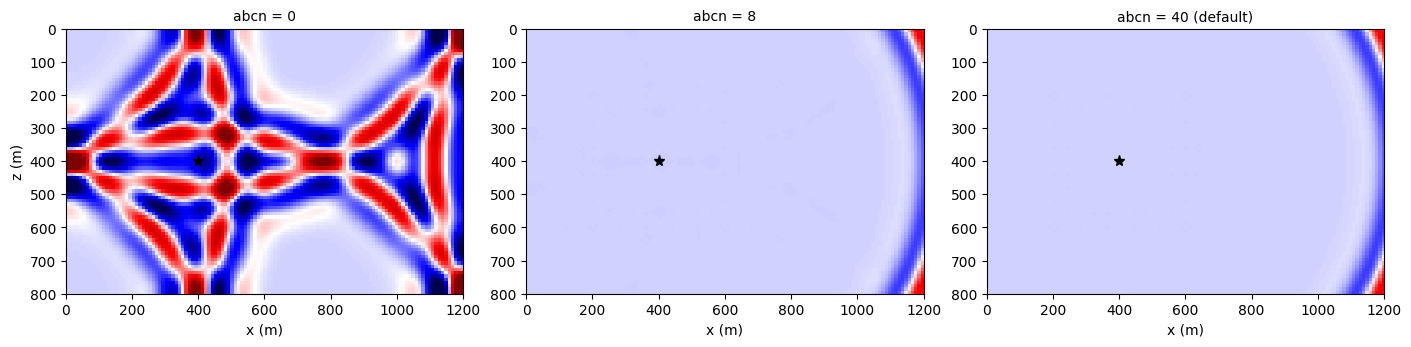

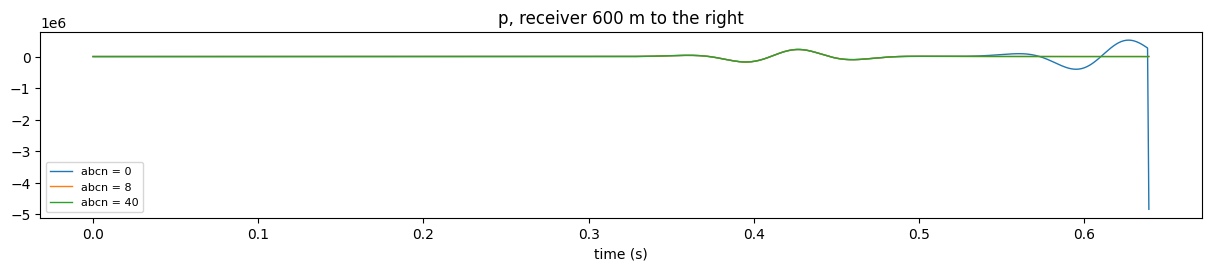

In [4]:
# one colour scale for the three, so the residual reflections compare directly
lim = np.percentile(imgs[0][imgs[0] != 0], [1, 99])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), constrained_layout=True)
for ax, (abcn, img) in zip(axes, imgs.items()):
    show(ax, img, f'abcn = {abcn}' + (' (default)' if abcn == 40 else ''), src[0], lim)
axes[0].set_ylabel('z (m)')
plt.show()

t = np.arange(nt) * dt
fig, ax = plt.subplots(figsize=(12, 2.6), constrained_layout=True)
for abcn, tr in traces.items():
    ax.plot(t, tr, lw=1, label=f'abcn = {abcn}')
ax.set_xlabel('time (s)'); ax.legend(fontsize=8); ax.set_title('p, receiver 600 m to the right')
plt.show()

With no layer every side reflects; on the same colour scale two elements of
C-PML already leave nothing visible, and the default ten elements give a margin
for grazing angles and lower frequencies. The wave at the right edge is the
direct wave, still leaving the model. The layer costs compute (it is part
of the mesh), so the default is a safe choice and a thinner one is a trade-off.
`abcn` is in grid cells and must be a multiple of `n_order`; one `abcn` applies
to every absorbing side.

## 3. Free surfaces

`free_surface` takes the same forms as on `PropTorch`:

- `True` — the top;
- edge names: `'top'`, `['top', 'left']` (2-D edges: `top`, `bottom`, `left`, `right`;
  3-D adds `front`, `back`);
- a dict `{'top': True, 'left': True}`.

A free side gets no absorbing layer. For an acoustic equation it is a
pressure-release surface: the reflection has the opposite polarity, where the
rigid side above had the same.

sweep: torch.compile is compiling the AcousticPotentialSEM2D step for a 81x121 grid


free_surface=True               -> ('top',), snapshot (3, 1, 1, 1, 121, 201)


sweep: torch.compile is compiling the AcousticPotentialSEM2D step for a 81x121 grid


free_surface=['top', 'left']    -> ('top', 'left'), snapshot (3, 1, 1, 1, 121, 161)


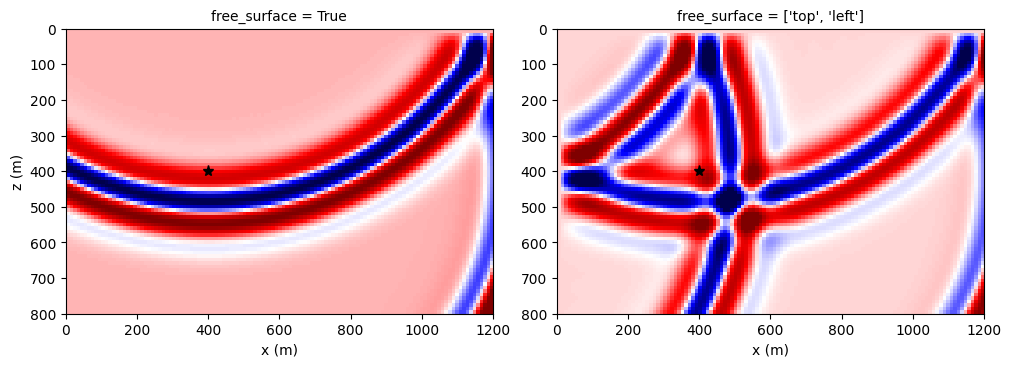

In [5]:
imgs = {}
for fs in (True, ['top', 'left']):
    solver = PropSEM(AcousticPotentialSEM2D, shape=shape, dh=dh, dt=dt,
                     n_order=n_order, free_surface=fs, f_dominant=f0,
                     impl='eager', device=device)
    with torch.no_grad():
        _, snaps = solver(wavelet, src, rec, models=[vp],
                          return_wavefield=True, snapshot_times=around)
    print(f'free_surface={fs!r:18s} -> {solver.free_surface}, snapshot {tuple(snaps.shape)}')
    imgs[str(fs)] = crop(pressure(snaps[:, 0, 0, 0].numpy()), solver)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for ax, (fs, img) in zip(axes, imgs.items()):
    show(ax, img, f'free_surface = {fs}', src[0])
axes[0].set_ylabel('z (m)')
plt.show()

## 4. Topography

`topography` puts a curved free surface on top (the mesh follows it; see
*SEM basics · 1*). An explosion under a 150 m hill in an elastic half-space,
three snapshots of the vertical particle velocity. We use the velocity–stress
equation here, whose field is the velocity itself. The snapshot is zero above
the surface; we blank it so the air shows white.

sweep: torch.compile is compiling the ElasticVSSEM2DDeformed step for a 101x241 grid


snapshot (3, 1, 1, 1, 141, 321) ['v_z']


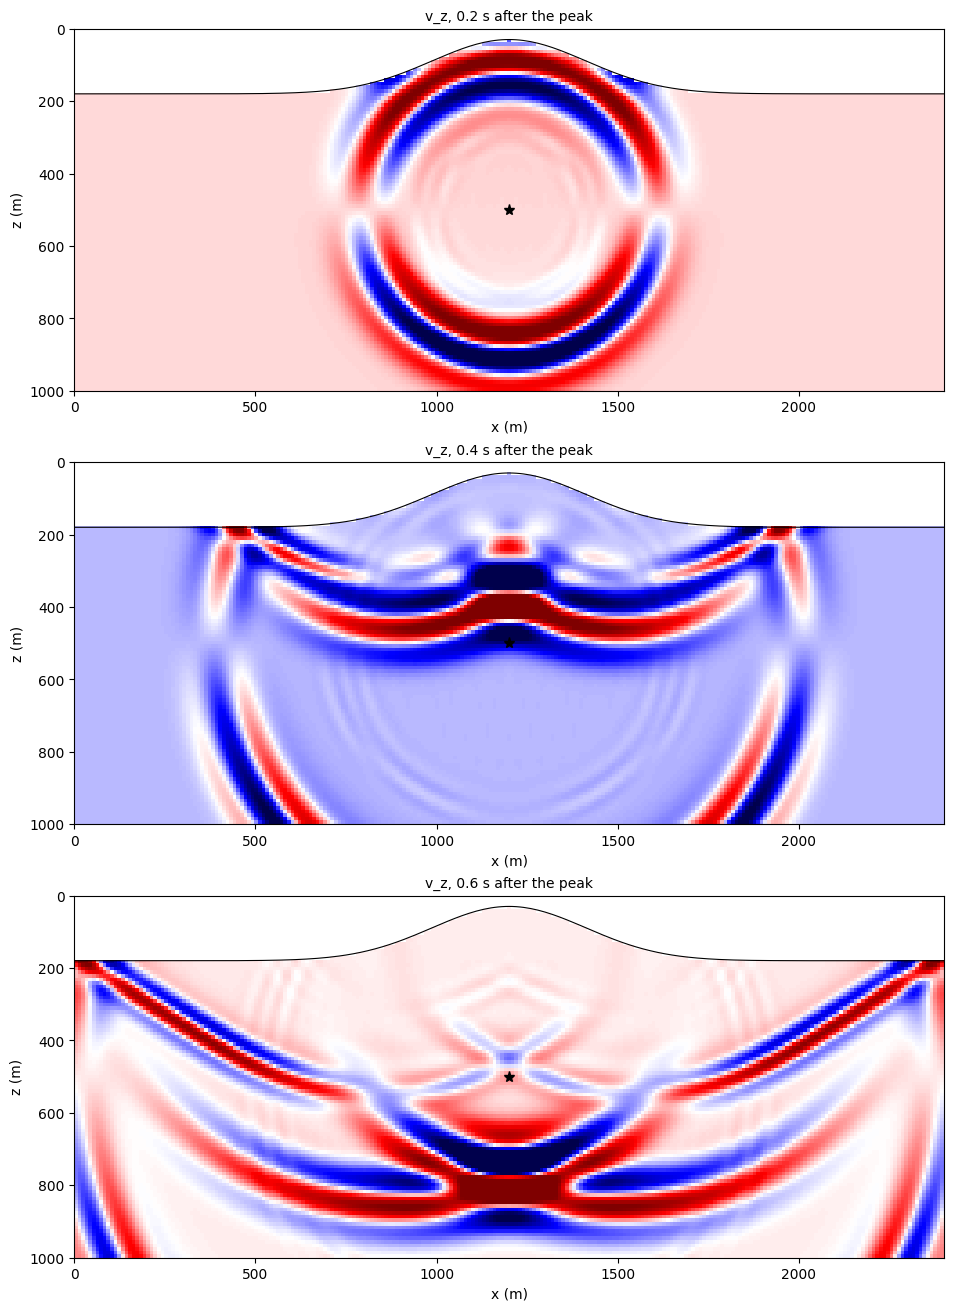

In [6]:
shape = (101, 241)                                       # 1 km x 2.4 km
ix = np.arange(shape[1])
topo = 18.0 - 15.0 * np.exp(-((ix - 120) / 30.0) ** 2)   # surface row: 180 m -> 30 m
vp  = torch.full(shape, 2000.0, device=device)
vs  = torch.full(shape, 1150.0, device=device)
rho = torch.full(shape, 2000.0, device=device)
nt = 1000
wavelet = ricker(np.arange(nt) * dt - delay, f=f0).astype(np.float32)
src = np.array([[120, 50]])                               # 500 m deep, under the crest
rx = np.arange(0, shape[1], 4)
rec = np.stack([rx, np.ceil(topo[rx]) + 1], axis=1)[None]  # just below the surface
steps = [int(round((delay + s) / dt)) for s in (0.2, 0.4, 0.6)]

solver = PropSEM(ElasticVSSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 topography=topo, f_dominant=f0, source_type=['sxx', 'szz'],
                 receiver_type=['vz'], impl='eager', device=device)
with torch.no_grad():
    seis, snaps = solver(wavelet, src, rec, models=[vp, vs, rho],
                         return_wavefield=True, snapshot_times=steps)
print('snapshot', tuple(snaps.shape), solver.snapshot_fields)

vz = crop(snaps[:, 0, 0, 0].numpy(), solver)              # (3, nz, nx): field v_z
air = np.arange(shape[0])[:, None] < topo[None, :]
vz[:, air] = np.nan
fig, axes = plt.subplots(3, 1, figsize=(12, 13), constrained_layout=True)
for ax, img, s in zip(axes, vz, (0.2, 0.4, 0.6)):
    show(ax, img, f'v_z, {s:.1f} s after the peak', src[0])
    ax.plot(ix * dh, topo * dh, 'k-', lw=0.8)
    ax.set_ylabel('z (m)')
plt.show()

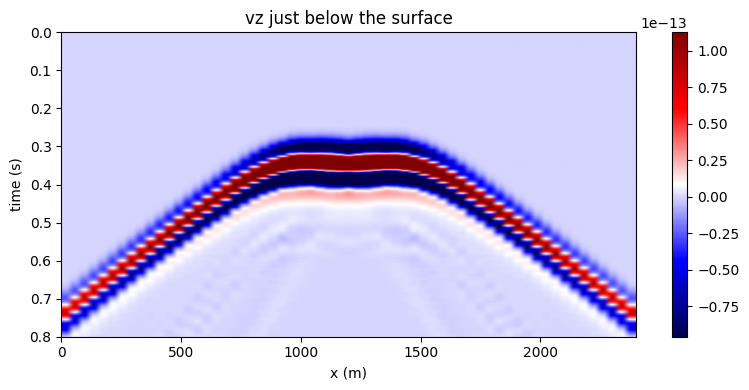

In [7]:
g = seis[0, :, :, 0].cpu().numpy()
lo, hi = np.percentile(g[g != 0], [2, 98])
plt.figure(figsize=(8, 4))
plt.imshow(g, cmap='seismic', vmin=lo, vmax=hi, aspect='auto',
           extent=[rx[0] * dh, rx[-1] * dh, nt * dt, 0])
plt.xlabel('x (m)'); plt.ylabel('time (s)'); plt.title('vz just below the surface')
plt.colorbar(); plt.tight_layout(); plt.show()

The P wave reaches the crest first; at the surface it converts into S waves and
Rayleigh waves that travel down the flanks. Receivers follow the surface here
(one row below it), which is how you place a surface spread on topography.

## 5. One rule for the velocity–stress solids

On the velocity–stress elastic and Biot equations (`ElasticVSSEM2DDeformed`,
`ElasticVTISEM2DDeformed`, `ElasticVSSEM3D*`, `Biot*`) a C-PML side may not run
between two free sides: the solid between them is a plate, and its
backward-propagating Lamb modes grow inside a PML. `PropSEM` refuses such a set-up
when it is called, and says how to fix it:

In [8]:
shape = (81, 121)
plate = PropSEM(ElasticVSSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                free_surface=['top', 'left', 'right'], f_dominant=f0, device=device)
models = [torch.full(shape, v, device=device) for v in (2000.0, 1150.0, 2000.0)]
try:
    plate(wavelet, np.array([[60, 40]]), np.array([[[30, 2]]]), models=models)
except ValueError as err:
    print(err)

ElasticVSSEM2DDeformed: the C-PML on ['bottom'] runs between the free 'left' and 'right' faces. The solid between them is a plate, whose backward-propagating (Lamb) modes a PML amplifies: the run grows without bound after a few seconds. Put an absorbing layer on 'left' or 'right' (free_surface on one of them only).


## Summary

| option | meaning |
| --- | --- |
| `abcn` | C-PML width in grid cells on every non-free side, a multiple of `n_order`; `None` = ten elements, `0` = rigid sides |
| `free_surface` | `True` (top), edge names, or `{edge: bool}`; free sides get no layer |
| `topography` | the surface row per column: a curved free surface on top |
| `return_wavefield=True` | `(record, snapshots)`, eager only; `snapshot_times` / `snapshot_interval` pick the steps |

Next: [SEM basics · 5 — gradients and memory](../54_sem_gradients_and_memory/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="53_sem_boundaries_and_snapshots.ipynb" download><code>53_sem_boundaries_and_snapshots.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/53_sem_boundaries_and_snapshots.ipynb">view on GitHub</a></p>